# HMM belief geometry: the latent structure lives in the belief state

Latent states walk a **ring**; each emits an observable token. The network sees only tokens, so the
latent ring lives in the **belief** `p(s_t | x_{1:t})` (the forward algorithm) — recovered in the
deep representation, not the token embedding. We check three things: behavior reaches Bayes
(`KL→0`), the belief is linearly represented (probe R²), and the ring appears in the deep reps.

In [1]:
import sys
import numpy as np, torch
from pyprojroot import here
sys.path.append(str(here()))
from src.code.geometry import predicted_geometry
from src.code.eval import cka
from src.code.train import train_inline
from src.code import plot_utils
from src.code.plot_utils import _pca2
import matplotlib.pyplot as plt

## Train a transformer on ring-HMM emissions

`runner=hmm` uses a transformer sized to reach Bayes on belief-tracking (the default tiny model under-fits). Informative emissions (`emission_kappa=8`).

In [2]:
model, ds, ev, hist = train_inline([
    'runner=hmm', 'emission_kappa=8.0', 'eval_kwargs.output_hidden_states=true'])
E_lat = predicted_geometry(ds.latent_conditional)          # predicted latent ring
n = ds.n_states

Current GPUs:
    GPU 0: NVIDIA H200
wandb disabled (wandb.enabled=false); skipping wandb.init.


INFO:src.code.models:Number of parameters: 402176


Model dims from dataset: vocab_size=25, max_position_embeddings=41


Step,Training Loss
100,2.483586
200,2.392818
300,2.381500
400,2.375524
500,2.373145
600,2.370725
700,2.372009
800,2.368966
900,2.366520
1000,2.367577


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

## Behavior reaches Bayes, and the belief is linearly represented

In [3]:
B, L = 96, 40
s = torch.empty(B, L, dtype=torch.long, device=ds.device)
s[:, 0] = torch.multinomial(ds.pi, B, replacement=True, generator=ds.rng)
for t in range(1, L):
    s[:, t] = torch.multinomial(ds.T[s[:, t-1]], 1, generator=ds.rng).squeeze(1)
x = torch.multinomial(ds.Em[s.reshape(-1)], 1, generator=ds.rng).reshape(B, L)
ids = torch.cat([torch.full((B,1), ds.start_token, dtype=torch.long, device=ds.device), x], 1)
with torch.no_grad():
    out = model(ids, output_hidden_states=True)

# behavior: KL(bayes || model) vs a marginal baseline
p_model = torch.softmax(out['logits'][:, :-1][..., ds.item_tokens], -1).cpu().numpy()
bel = ds.forward_algorithm(x)
p_bayes = torch.cat([(ds.pi @ ds.Em).expand(B,1,-1), (bel[:, :-1] @ ds.T) @ ds.Em], 1).cpu().numpy()
kl = lambda p, q: float((p * (np.log(p+1e-9) - np.log(q+1e-9))).sum(-1).mean())
KL_model = kl(p_bayes, p_model); KL_base = kl(p_bayes, (ds.pi @ ds.Em).cpu().numpy()[None, None])

# representation: linear probe hidden -> full belief (held-out R2) + CKA to the belief-code
H = out['hidden_states'][-1][:, 1:].reshape(-1, model.config.hidden_size).cpu().numpy()
belf = bel.reshape(-1, n).cpu().numpy()
ntr = int(0.8 * len(H)); lam = 1e-2
Xtr = np.c_[H[:ntr], np.ones(ntr)]; Xte = np.c_[H[ntr:], np.ones(len(H)-ntr)]
W = np.linalg.solve(Xtr.T@Xtr + lam*np.eye(Xtr.shape[1]), Xtr.T@belf[:ntr]); pred = Xte @ W
R2 = 1 - ((belf[ntr:]-pred)**2).sum() / ((belf[ntr:]-belf[ntr:].mean(0))**2).sum()
print(f'behavior : KL(bayes||model) = {KL_model:.4f}   (marginal baseline {KL_base:.3f})')
print(f'belief   : linear-probe R2 = {R2:.3f}   CKA(belief-code) = {cka(H, belf@E_lat):.3f}')

behavior : KL(bayes||model) = 0.0044   (marginal baseline 0.524)


belief   : linear-probe R2 = 0.958   CKA(belief-code) = 0.913


## The latent ring appears in the deep representation

Averaging the deep reps by the true latent state recovers the ring (a token alone can't — emissions are decoupled from state geometry; the ring is reconstructed in belief space).

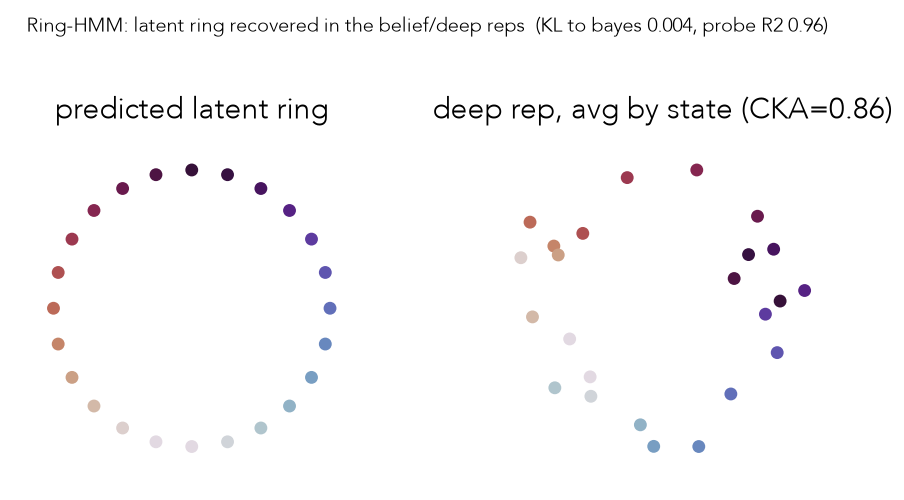

In [4]:
st = s.cpu().numpy().reshape(-1)
deep = np.vstack([H[st == k].mean(0) for k in range(n)])
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
plot_utils.scatter_geometry(ax[0], E_lat[:, :2], 'predicted latent ring')
plot_utils.scatter_geometry(ax[1], _pca2(deep), f'deep rep, avg by state (CKA={cka(deep, E_lat):.2f})')
fig.suptitle(f'Ring-HMM: latent ring recovered in the belief/deep reps  '
             f'(KL to bayes {KL_model:.3f}, probe R2 {R2:.2f})', y=1.03)
fig.tight_layout(); fig.savefig(here()/'hmm_belief_geometry.png', bbox_inches='tight', dpi=130);